<a href="https://colab.research.google.com/github/Archer-Read/MMA3001-Project/blob/main/Concrete_Strength_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Dataset Loading



In [13]:
# Import pandas for data handling
import pandas as pd

# Load the concrete dataset directly from GitHub
url = "https://raw.githubusercontent.com/Archer-Read/MMA3001-Project/main/Concrete_Data.xls"

df = pd.read_excel(url)

# Display the first five observations
df.head()

,Cement (component 1)(kg in a m^3 mixture),Blast Furnace Slag (component 2)(kg in a m^3 mixture),Fly Ash (component 3)(kg in a m^3 mixture),Water (component 4)(kg in a m^3 mixture),Superplasticizer (component 5)(kg in a m^3 mixture),Coarse Aggregate (component 6)(kg in a m^3 mixture),Fine Aggregate (component 7)(kg in a m^3 mixture),Age (day),"Concrete compressive strength(MPa, megapascals)"
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075


# Data Inspection
The dataset is inspected to confirm its dimensions, identify the data types of each variable and check for missing values. This ensures that the data is suitable for use in the regression models.

In [14]:
#Dsiplay no. of observations and variables
print("Dataset shape:", df.shape)

#Display data types
df.info()

#Check for missing values
df.isnull().sum()

Dataset shape: (1030, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column                                                 Non-Null Count  Dtype  
---  ------                                                 --------------  -----  
 0   Cement (component 1)(kg in a m^3 mixture)              1030 non-null   float64
 1   Blast Furnace Slag (component 2)(kg in a m^3 mixture)  1030 non-null   float64
 2   Fly Ash (component 3)(kg in a m^3 mixture)             1030 non-null   float64
 3   Water  (component 4)(kg in a m^3 mixture)              1030 non-null   float64
 4   Superplasticizer (component 5)(kg in a m^3 mixture)    1030 non-null   float64
 5   Coarse Aggregate  (component 6)(kg in a m^3 mixture)   1030 non-null   float64
 6   Fine Aggregate (component 7)(kg in a m^3 mixture)      1030 non-null   float64
 7   Age (day)                                              1030 non-null   int64  
 8   Concrete compressive str

,0
Cement (component 1)(kg in a m^3 mixture),0
Blast Furnace Slag (component 2)(kg in a m^3 mixture),0
Fly Ash (component 3)(kg in a m^3 mixture),0
Water (component 4)(kg in a m^3 mixture),0
Superplasticizer (component 5)(kg in a m^3 mixture),0
Coarse Aggregate (component 6)(kg in a m^3 mixture),0
Fine Aggregate (component 7)(kg in a m^3 mixture),0
Age (day),0
"Concrete compressive strength(MPa, megapascals)",0


# Data Preparation
Before modelling takes place, the data must be formatted by separating the input and output variables. Also, the observations need to be divided into training, validation and testing datasets.

**Splitting inputs and outputs**

In [15]:
# Separate the eight input variables from the output variable
X = df.iloc[:, :-1]
y = df.iloc[:, -1]

# Check the dimensions of the inputs and output
print("Input shape:", X.shape)
print("Output shape:", y.shape)

Input shape: (1030, 8)
Output shape: (1030,)


**Training, Validation and Testing Data**

The dataset is divided into three subsets to allow the regression models to be developed and evaluated.

- Training data (60%): Used to train the regression models.
- Validation data (20%): Used to compare model settings and select suitable parameters.
- Testing data (20%): Reserved for the final evaluation of model performance on unseen observations.

A fixed random state is used to ensure that the data splitting process is reproducible.

In [16]:
from sklearn.model_selection import train_test_split

# Split the dataset into 80% development data and 20% testing data
X_development, X_test, y_development, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Split the development data into training and validation sets
X_train, X_val, y_train, y_val = train_test_split(
    X_development, y_development, test_size=0.25, random_state=42
)

# Display the number of observations in each subset
print("Training observations:", len(X_train))
print("Validation observations:", len(X_val))
print("Testing observations:", len(X_test))

Training observations: 618
Validation observations: 206
Testing observations: 206


#Linear Regression
We are using linear regression as the baseline model to predict concrete compressive strength. This model estimates how the eight input variables affect concrete compressive strength by fitting a linear equation to the training data.It was chosen to do this because it provides a simple baseline to then compare with the later models constructed, however, it may struggle to capture potentially more complex, non-linear relationships between the inputs and the output.

In [17]:
# Import the Linear Regression model
from sklearn.linear_model import LinearRegression

# Create the Linear Regression model
linear_model = LinearRegression()

# Train the model using the training data
linear_model.fit(X_train, y_train)

LinearRegression()

In [18]:
# Display the linear regression equation
equation = f"Compressive Strength (MPa) = {linear_model.intercept_:.4f}"

# Add each input variable and its coefficient
for variable, coefficient in zip(X_train.columns, linear_model.coef_):
    equation += f" {coefficient:+.4f} × ({variable})"

print(equation)

Compressive Strength (MPa) = -26.7487 +0.1140 × (Cement (component 1)(kg in a m^3 mixture)) +0.1031 × (Blast Furnace Slag (component 2)(kg in a m^3 mixture)) +0.0790 × (Fly Ash (component 3)(kg in a m^3 mixture)) -0.1264 × (Water  (component 4)(kg in a m^3 mixture)) +0.3840 × (Superplasticizer (component 5)(kg in a m^3 mixture)) +0.0157 × (Coarse Aggregate  (component 6)(kg in a m^3 mixture)) +0.0240 × (Fine Aggregate (component 7)(kg in a m^3 mixture)) +0.1203 × (Age (day))


#The Linear Model Created
**Compressive Strength (MPa)** = -26.7487 + 0.1140 × **Cement** + 0.1031 × **Blast Furnace Slag** + 0.0790 × **Fly Ash** - 0.1264 × **Water** + 0.3840 × **Superplasticizer** + 0.0157 × **Coarse Aggregate** + 0.0240 × **Fine Aggregate** + 0.1203 × **Age**

In [19]:
# Predict concrete compressive strength using the validation data
y_pred_linear = linear_model.predict(X_val)

# Display the first five predictions
print("First five predicted strengths (MPa):")
print(y_pred_linear[:5])

First five predicted strengths (MPa):
[32.16868881 64.89049838 24.27743503 25.37293998 59.40569746]


In [20]:
# Create a table comparing actual and predicted strengths
comparison = pd.DataFrame({
    "Actual Strength (MPa)": y_val.values,
    "Predicted Strength (MPa)": y_pred_linear
})

# Display the first five observations
comparison.head()

,Actual Strength (MPa),Predicted Strength (MPa)
0,7.749710,32.168689
1,56.399137,64.890498
2,32.039950,24.277435
3,13.089012,25.372940
4,43.012960,59.405697


#Evaluation of Linear Regression


In [21]:
# Import regression performance metrics
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Calculate performance using the validation dataset
r2 = r2_score(y_val, y_pred_linear)
mae = mean_absolute_error(y_val, y_pred_linear)
rmse = np.sqrt(mean_squared_error(y_val, y_pred_linear))

# Display the results
print(f"R²: {r2:.4f}")
print(f"MAE: {mae:.4f} MPa")
print(f"RMSE: {rmse:.4f} MPa")

R²: 0.6256
MAE: 8.6123 MPa
RMSE: 10.6841 MPa


The Linear Regression model achieved an R² of 0.6256, indicating that approximately 62.56% of the variation in concrete compressive strength within the validation dataset was explained by the model.

The model produced a Mean Absolute Error (MAE) of 8.6123 MPa and a Root Mean Squared Error (RMSE) of 10.6841 MPa. These results indicate that the model has moderate predictive accuracy, with some relatively large prediction errors.

One possible limitation is the assumption of a linear relationship between the input variables and compressive strength. In reality, concrete strength may depend on nonlinear interactions between mixture composition and curing age.

These results will serve as the baseline for comparison with Decision Tree Regression, which may be better suited to capturing nonlinear relationships.

#Decision Tree Regression
Decision tree regression is being performed as an alternative model.
Unlike linear regresssion, decisision tree has the ability to capture potential non-linear relationships between the eight input variables and compressive strength.
An initial Decision Tree model will be trained using default parameters. Its performance will then be evaluated and compared with Linear Regression. The effect of changing the maximum tree depth will also be investigated to assess model complexity and potential overfitting.

#Baseline Decision Tree Regression (Default Parameters)

In [22]:
# Import the Decision Tree Regression model
from sklearn.tree import DecisionTreeRegressor

# Create a Decision Tree model with default parameters
tree_model = DecisionTreeRegressor(random_state=42)

# Train the model using the training dataset
tree_model.fit(X_train, y_train)

DecisionTreeRegressor(random_state=42)

In [23]:
# Predict compressive strength using the validation dataset
y_pred_tree = tree_model.predict(X_val)

# Create a table comparing actual and predicted strengths
tree_comparison = pd.DataFrame({
    "Actual Strength (MPa)": y_val.values,
    "Predicted Strength (MPa)": y_pred_tree
})

# Display the first five observations
tree_comparison.head()

,Actual Strength (MPa),Predicted Strength (MPa)
0,7.749710,21.780547
1,56.399137,58.798513
2,32.039950,27.923778
3,13.089012,15.691095
4,43.012960,41.836714


#Baseline Model Performance

In [24]:
# Calculate Decision Tree performance metrics
tree_r2 = r2_score(y_val, y_pred_tree)
tree_mae = mean_absolute_error(y_val, y_pred_tree)
tree_rmse = np.sqrt(mean_squared_error(y_val, y_pred_tree))

# Display the results
print(f"R²: {tree_r2:.4f}")
print(f"MAE: {tree_mae:.4f} MPa")
print(f"RMSE: {tree_rmse:.4f} MPa")

R²: 0.8289
MAE: 4.5317 MPa
RMSE: 7.2235 MPa


The Decision Tree Regression model achieved an R² of 0.8289, a Mean Absolute Error (MAE) of 4.5317 MPa, and a Root Mean Squared Error (RMSE) of 7.2235 MPa on the validation dataset.

Compared with Linear Regression, the Decision Tree achieved a higher R² and reduced MAE by approximately 47.4%. This indicates that Decision Tree Regression is more effective at capturing the relationships between concrete mixture composition, curing age, and compressive strength.

However, Decision Trees can be susceptible to overfitting, particularly when allowed to grow without a maximum depth restriction. Further investigation is therefore required to determine whether limiting tree depth can improve generalisation to unseen data.

#Maximum Tree Depth Sensitivty Analysis

In [28]:
# Test different maximum tree depths
depths = range(1,21)
train_rmse = []
val_rmse = []

for depth in depths:

    # Create and train a Decision Tree with the selected depth
    model = DecisionTreeRegressor(max_depth=depth, random_state=42)
    model.fit(X_train, y_train)

    # Predict using training and validation data
    train_predictions = model.predict(X_train)
    val_predictions = model.predict(X_val)

    # Calculate RMSE for both datasets
    train_rmse.append(np.sqrt(mean_squared_error(y_train, train_predictions)))
    val_rmse.append(np.sqrt(mean_squared_error(y_val, val_predictions)))

# Display results in a table
depth_results = pd.DataFrame({
    "Max Depth": depths,
    "Training RMSE (MPa)": train_rmse,
    "Validation RMSE (MPa)": val_rmse
})

print(depth_results.to_string(index=False))

# Identify the depth with the lowest validation RMSE
best_depth = depth_results.loc[
    depth_results["Validation RMSE (MPa)"].idxmin(), "Max Depth"
]

print(f"\nBest maximum depth: {best_depth}")

 Max Depth  Training RMSE (MPa)  Validation RMSE (MPa)
         1            14.298535              15.222537
         2            11.870831              12.660214
         3            10.072583              10.533146
         4             8.712434               8.766976
         5             7.378598               7.869986
         6             6.068094               7.353142
         7             4.652799               6.845662
         8             3.819249               6.888349
         9             2.909129               6.861428
        10             2.243630               6.532336
        11             1.708195               6.699452
        12             1.309559               6.146854
        13             1.116502               6.668740
        14             1.011394               6.730309
        15             0.974787               6.800310
        16             0.968048               6.580538
        17             0.965767               7.059894
        18

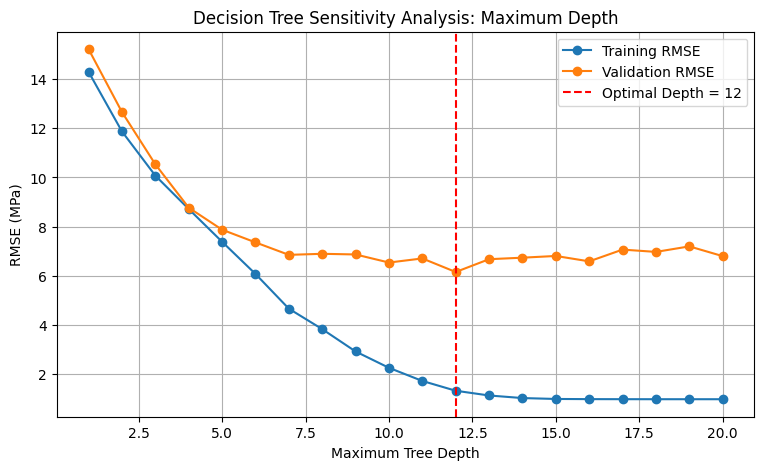

In [26]:
# Import plotting library
import matplotlib.pyplot as plt

# Plot training and validation RMSE against maximum tree depth
plt.figure(figsize=(9, 5))

plt.plot(depths, train_rmse, marker='o', label='Training RMSE')
plt.plot(depths, val_rmse, marker='o', label='Validation RMSE')

# Highlight the optimal maximum depth
plt.axvline(x=best_depth, color='red', linestyle='--',
            label=f'Optimal Depth = {best_depth}')

# Add labels and title
plt.xlabel('Maximum Tree Depth')
plt.ylabel('RMSE (MPa)')
plt.title('Decision Tree Sensitivity Analysis: Maximum Depth')
plt.legend()
plt.grid(True)

A sensitivity analysis was conducted to investigate the effect of maximum tree depth on Decision Tree Regression performance. Maximum depths ranging from 1 to 20 were tested, with training and validation RMSE calculated for each model.

The lowest validation RMSE of 6.1469 MPa occurred at a maximum depth of 12. This represents an improvement of approximately 14.9% compared with the baseline Decision Tree model, which achieved an RMSE of 7.2235 MPa.

These results demonstrate that adjusting model complexity can improve predictive performance. A maximum depth of 12 was therefore selected for the optimised Decision Tree model.

The training and validation RMSE curves can also be examined to identify potential underfitting and overfitting as tree depth increases.

#Optimised Decision Tree Regression

In [29]:
# Create the optimised Decision Tree model
optimised_tree = DecisionTreeRegressor(
    max_depth=12,
    random_state=42
)

# Train the model
optimised_tree.fit(X_train, y_train)

# Predict concrete strength using validation data
y_pred_optimised = optimised_tree.predict(X_val)

# Calculate performance metrics
optimised_r2 = r2_score(y_val, y_pred_optimised)
optimised_mae = mean_absolute_error(y_val, y_pred_optimised)
optimised_rmse = np.sqrt(mean_squared_error(y_val, y_pred_optimised))

# Display results
print(f"R²: {optimised_r2:.4f}")
print(f"MAE: {optimised_mae:.4f} MPa")
print(f"RMSE: {optimised_rmse:.4f} MPa")

R²: 0.8761
MAE: 4.2343 MPa
RMSE: 6.1469 MPa


Following the maximum depth sensitivity analysis, a Decision Tree Regression model was trained using an optimal maximum depth of 12.

The optimised model achieved an R² of 0.8761, a Mean Absolute Error (MAE) of 4.2343 MPa, and a Root Mean Squared Error (RMSE) of 6.1469 MPa on the validation dataset.

Compared with the default Decision Tree model, the optimised model reduced RMSE by approximately 14.9%. This suggests that restricting the maximum tree depth improved generalisation by reducing excessive model complexity.

The optimised Decision Tree also outperformed Linear Regression across all three evaluation metrics, indicating that a nonlinear model is better suited to predicting concrete compressive strength for this dataset.

### Model Validation Performance Comparison

| Metric | Linear Regression | Default Decision Tree | Optimised Decision Tree |
|---|---:|---:|---:|
| **R²** | 0.6256 | 0.8289 | **0.8761** |
| **MAE (MPa)** | 8.6123 | 4.5317 | **4.2343** |
| **RMSE (MPa)** | 10.6841 | 7.2235 | **6.1469** |

#Final Model Comparison
Following model development and hyperparameter optimisation, Linear Regression and the optimised Decision Tree were evaluated using the previously unseen test dataset.

The test dataset contains 206 observations, representing 20% of the original dataset. These observations were excluded from model training and hyperparameter selection.

Both models were evaluated using R², MAE, and RMSE to assess their predictive accuracy and ability to generalise to unseen concrete samples.

In [30]:
# Generate predictions using the unseen test dataset
y_test_linear = linear_model.predict(X_test)
y_test_tree = optimised_tree.predict(X_test)

# Calculate Linear Regression test metrics
linear_test_r2 = r2_score(y_test, y_test_linear)
linear_test_mae = mean_absolute_error(y_test, y_test_linear)
linear_test_rmse = np.sqrt(mean_squared_error(y_test, y_test_linear))

# Calculate Optimised Decision Tree test metrics
tree_test_r2 = r2_score(y_test, y_test_tree)
tree_test_mae = mean_absolute_error(y_test, y_test_tree)
tree_test_rmse = np.sqrt(mean_squared_error(y_test, y_test_tree))

# Create a comparison table
test_results = pd.DataFrame({
    "Model": ["Linear Regression", "Optimised Decision Tree"],
    "R²": [linear_test_r2, tree_test_r2],
    "MAE (MPa)": [linear_test_mae, tree_test_mae],
    "RMSE (MPa)": [linear_test_rmse, tree_test_rmse]
})

# Display results rounded to four decimal places
print(test_results.round(4).to_string(index=False))

                  Model     R²  MAE (MPa)  RMSE (MPa)
      Linear Regression 0.6263     7.7392      9.8127
Optimised Decision Tree 0.7766     5.1536      7.5867


#Test Data Results

| Metric | Linear Regression | Optimised Decision Tree |
|---|---:|---:|
| **R²** | 0.6263 | **0.7766** |
| **MAE (MPa)** | 7.7392 | **5.1536** |
| **RMSE (MPa)** | 9.8127 | **7.5867** |

The Optimised Decision Tree Regression model outperformed Linear Regression across all three performance metrics on the previously unseen test dataset.

The Optimised Decision Tree achieved an R² of 0.7766, compared with 0.6263 for Linear Regression. It also reduced MAE from 7.7392 MPa to 5.1536 MPa and RMSE from 9.8127 MPa to 7.5867 MPa.

However, the Optimised Decision Tree's test RMSE was higher than its validation RMSE of 6.1469 MPa, indicating that its performance on unseen observations was weaker than during validation.

Overall, the results suggest that Decision Tree Regression is better suited to modelling the nonlinear relationships between concrete mixture composition, curing age, and compressive strength. Nevertheless, prediction errors remain, and the model should not replace experimental strength testing when making safety-critical engineering decisions.

#Model Visualisation and Engineering Interpretation

#Actual vs Model Predicted Concrete Strength

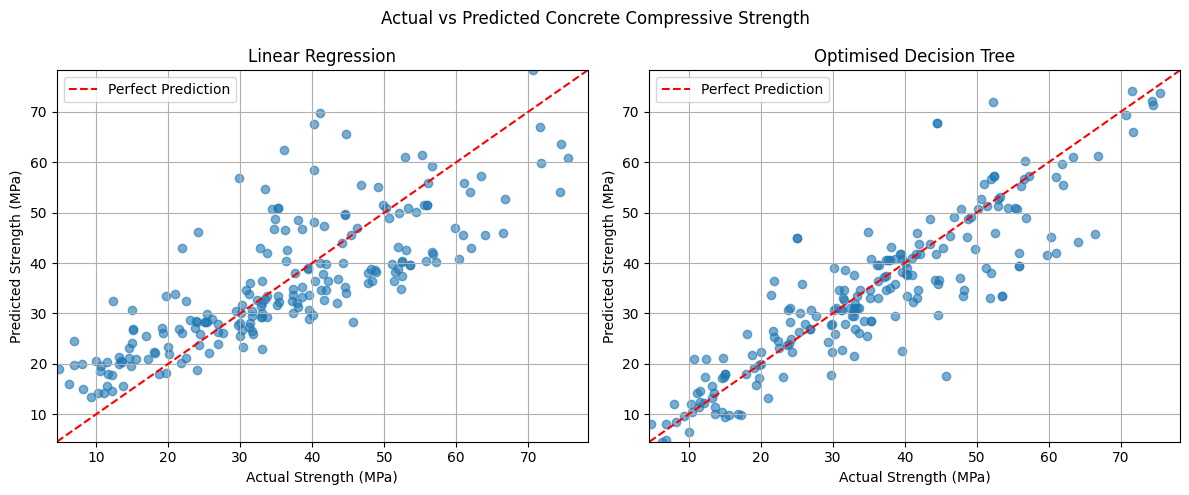

In [31]:
import matplotlib.pyplot as plt

# Create two graphs side by side
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Models and predictions
models = [
    ("Linear Regression", y_test_linear),
    ("Optimised Decision Tree", y_test_tree)
]

# Use the same axis limits for a fair comparison
axis_min = min(y_test.min(), y_test_linear.min(), y_test_tree.min())
axis_max = max(y_test.max(), y_test_linear.max(), y_test_tree.max())

for ax, (name, predictions) in zip(axes, models):

    # Plot actual against predicted compressive strength
    ax.scatter(y_test, predictions, alpha=0.6)

    # Perfect prediction reference line
    ax.plot([axis_min, axis_max], [axis_min, axis_max],
            'r--', label='Perfect Prediction')

    ax.set_xlabel("Actual Strength (MPa)")
    ax.set_ylabel("Predicted Strength (MPa)")
    ax.set_title(name)
    ax.set_xlim(axis_min, axis_max)
    ax.set_ylim(axis_min, axis_max)
    ax.legend()
    ax.grid(True)

plt.suptitle("Actual vs Predicted Concrete Compressive Strength")
plt.tight_layout()
plt.show()

#Residual Analysis
Residual analysis was conducted to investigate the prediction errors of Linear Regression and the Optimised Decision Tree.

Residuals were calculated as the difference between actual and predicted compressive strength. A residual of zero indicates a perfect prediction, while positive and negative residuals indicate underprediction and overprediction, respectively.

Residual plots were used to assess whether the models exhibit systematic prediction errors across different concrete compressive strengths.

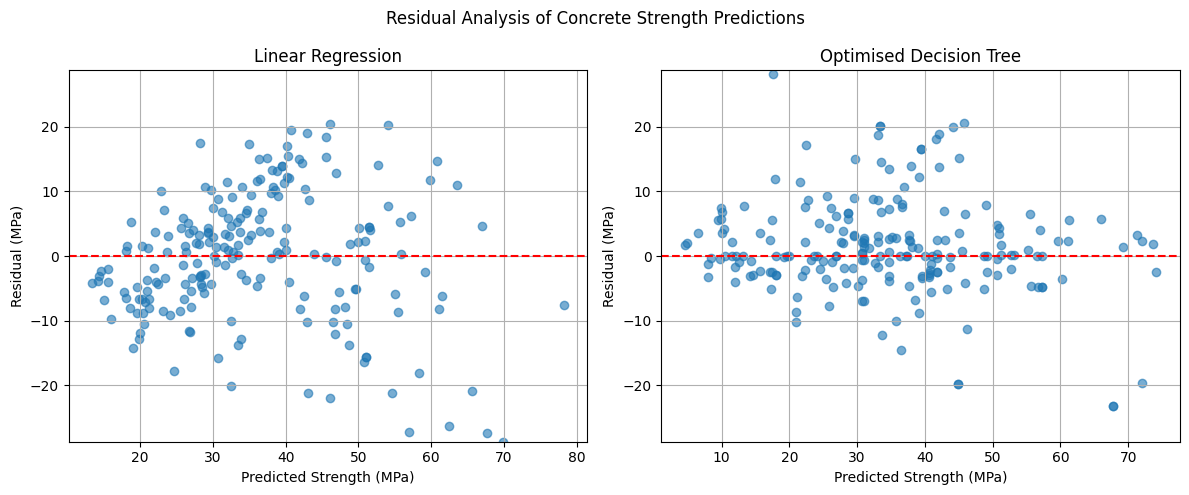

In [32]:
# Calculate residuals for both models
linear_residuals = y_test - y_test_linear
tree_residuals = y_test - y_test_tree

# Create residual plots side by side
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

models = [
    ("Linear Regression", y_test_linear, linear_residuals),
    ("Optimised Decision Tree", y_test_tree, tree_residuals)
]

# Use the same vertical scale for both graphs
residual_limit = max(
    abs(linear_residuals).max(),
    abs(tree_residuals).max()
)

for ax, (name, predictions, residuals) in zip(axes, models):

    # Plot residuals against predicted strengths
    ax.scatter(predictions, residuals, alpha=0.6)

    # Add a reference line at zero residual
    ax.axhline(y=0, color='red', linestyle='--')

    ax.set_xlabel("Predicted Strength (MPa)")
    ax.set_ylabel("Residual (MPa)")
    ax.set_title(name)
    ax.set_ylim(-residual_limit, residual_limit)
    ax.grid(True)

plt.suptitle("Residual Analysis of Concrete Strength Predictions")
plt.tight_layout()
plt.show()

The residual plots demonstrate differences in the prediction errors produced by Linear Regression and the Optimised Decision Tree.

Linear Regression exhibits a noticeable curved pattern in its residuals, suggesting that the model does not adequately capture the nonlinear relationships between concrete composition, curing age, and compressive strength. Several large positive and negative residuals are also observed.

In comparison, the Optimised Decision Tree produces residuals that are generally more concentrated around zero, with a less pronounced systematic pattern. This supports the model's superior predictive performance, demonstrated by its lower test RMSE of 7.5867 MPa, compared with 9.8127 MPa for Linear Regression.

However, the Decision Tree still produces some substantial prediction errors, indicating that it cannot accurately predict every concrete mixture.

From an engineering perspective, negative residuals are particularly important because they indicate that the model has overestimated the actual compressive strength. Such errors could be problematic if predictions were used to assess whether concrete meets structural strength requirements.

Therefore, although the Optimised Decision Tree provides better overall accuracy, its predictions should not replace experimental testing or established engineering verification procedures.

#Feature Significance Analysis
Feature importance analysis was conducted to identify which input variables contribute most strongly to the Optimised Decision Tree's predictions of concrete compressive strength.

The analysis uses the feature importance scores calculated by the Decision Tree model. These scores measure the relative contribution of each variable to reducing prediction error during tree construction.

Understanding feature importance helps interpret the model's behaviour and assess whether its predictions are consistent with engineering expectations.

In [33]:
# Extract feature importance scores from the optimised model
importance = optimised_tree.feature_importances_

# Create a table of feature importance scores
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": importance
})

# Sort features from most to least important
feature_importance = feature_importance.sort_values(
    by="Importance", ascending=False
)

# Display the results
print(feature_importance.to_string(index=False))

                                              Feature  Importance
            Cement (component 1)(kg in a m^3 mixture)    0.382159
                                            Age (day)    0.325235
            Water  (component 4)(kg in a m^3 mixture)    0.119143
Blast Furnace Slag (component 2)(kg in a m^3 mixture)    0.103388
  Superplasticizer (component 5)(kg in a m^3 mixture)    0.024696
 Coarse Aggregate  (component 6)(kg in a m^3 mixture)    0.021678
    Fine Aggregate (component 7)(kg in a m^3 mixture)    0.018547
           Fly Ash (component 3)(kg in a m^3 mixture)    0.005153


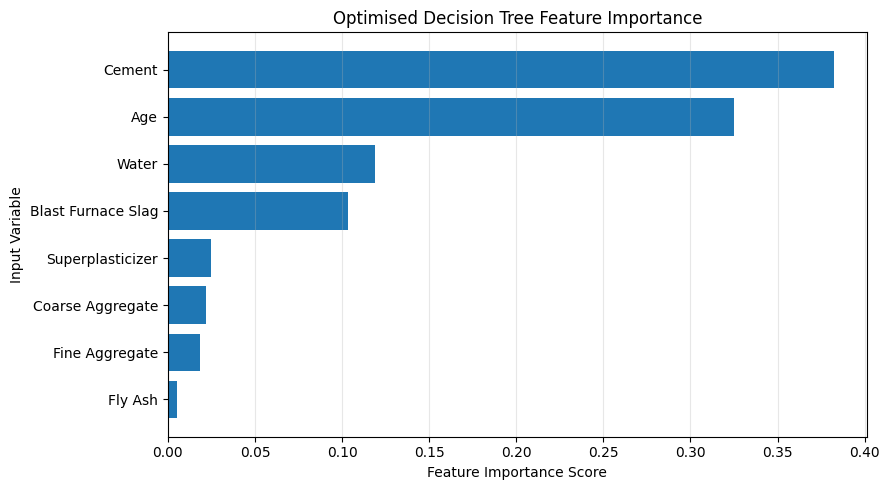

In [35]:
# Shorten the feature names for the graph
short_names = [
    "Cement", "Blast Furnace Slag", "Fly Ash", "Water",
    "Superplasticizer", "Coarse Aggregate", "Fine Aggregate", "Age"
]

# Create a table with shorter feature names
feature_importance_clean = pd.DataFrame({
    "Feature": short_names,
    "Importance": optimised_tree.feature_importances_
})

# Sort features by importance
feature_importance_clean = feature_importance_clean.sort_values(
    by="Importance", ascending=False
)

# Plot feature importance
plt.figure(figsize=(9, 5))

plt.barh(
    feature_importance_clean["Feature"],
    feature_importance_clean["Importance"]
)

plt.gca().invert_yaxis()

plt.xlabel("Feature Importance Score")
plt.ylabel("Input Variable")
plt.title("Optimised Decision Tree Feature Importance")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

The feature importance analysis identified cement content and curing age as the two most influential variables in the Optimised Decision Tree, with approximate importance scores of 0.38 and 0.32, respectively.

Water content and blast furnace slag were the next most influential variables, while superplasticizer, coarse aggregate, fine aggregate, and fly ash had relatively low importance scores.

These findings are consistent with engineering expectations. Cement content influences the hydration reactions responsible for strength development, while curing age affects the time available for these reactions to occur. Water content also influences compressive strength through its relationship with the water-to-cement ratio.

However, feature importance scores represent the variables' contributions to the model's predictions rather than direct physical or causal relationships. Low importance scores do not necessarily indicate that a material has little effect on concrete strength.

Overall, the results suggest that the Optimised Decision Tree captures relationships that are relevant to the engineering behaviour of concrete.